# Gold 통합 데이터 EDA

- 데이터: `project/data/model_datasets/unified/gold_unified.csv` (4,669행 × 79열)
- 스키마·생성 규칙: `project/md/gold_unified_schema.md`
- 한 행 = 상품 1개, 통합 키 = `출처 + 상품ID`

## 0. 환경 설정

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 한글 폰트 (Windows: 맑은 고딕)
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 차트 스타일: 옅은 그리드, 얇은 축
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "figure.dpi": 110,
})

# 출처별 고정 색상 (순위가 아닌 출처에 색을 고정)
SOURCE_ORDER = ["danawa", "zooplus", "petsathome", "petsmart"]
SOURCE_COLOR = dict(zip(SOURCE_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))

pd.set_option("display.max_rows", 100)

## 1. 데이터 로드

In [2]:
DATA_PATH = Path("../data/model_datasets/unified/gold_unified.csv")
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig", low_memory=False)
df["출처"] = pd.Categorical(df["출처"], categories=SOURCE_ORDER)

print(f"행 수: {df.shape[0]:,} / 열 수: {df.shape[1]}")
print(f"통합 키(출처+상품ID) 중복: {df.duplicated(['출처', '상품ID']).sum()}")
df["출처"].value_counts().rename("상품 수").to_frame()

행 수: 4,669 / 열 수: 79
통합 키(출처+상품ID) 중복: 0


,상품 수
출처,
danawa,1830
zooplus,1690
petsathome,670
petsmart,479


## 2. `기능_원문`의 종류

`기능_원문`은 상품에 붙은 건강 기능 라벨의 원문이며, 한 상품에 여러 라벨이 `|`로 이어져 있다 (예: `소화·장건강|피부·모질개선`).
라벨 종류를 세기 위해 라벨 1개 = 1행으로 펼친다.

In [3]:
labels = (df[["출처", "상품ID", "기능_원문"]]
          .assign(라벨=df["기능_원문"].str.split("|"))
          .explode("라벨"))
labels["라벨"] = labels["라벨"].str.strip()

n_labels = df["기능_원문"].str.split("|").str.len()
print(f"고유 라벨 수: {labels['라벨'].nunique()}")
print(f"상품당 라벨 수: 평균 {n_labels.mean():.2f}, 중앙값 {n_labels.median():.0f}, 최대 {n_labels.max()}")

summary = labels.groupby("출처", observed=True).agg(고유_라벨_수=("라벨", "nunique"), 라벨_부착_건수=("라벨", "size"))
summary["상품_수"] = df["출처"].value_counts()
summary["상품당_평균_라벨"] = (summary["라벨_부착_건수"] / summary["상품_수"]).round(2)
shared = labels.groupby("라벨")["출처"].nunique()
print(f"2개 이상 출처에 함께 나오는 라벨: {(shared > 1).sum()}개")
summary

고유 라벨 수: 79
상품당 라벨 수: 평균 1.81, 중앙값 1, 최대 12
2개 이상 출처에 함께 나오는 라벨: 0개


,고유_라벨_수,라벨_부착_건수,상품_수,상품당_평균_라벨
출처,,,,
danawa,16,4301,1830,2.35
zooplus,26,2630,1690,1.56
petsathome,13,803,670,1.20
petsmart,24,710,479,1.48


### 2-1. 출처별 기능 라벨 빈도 (막대그래프)

출처마다 라벨 어휘가 달라 출처별로 그래프를 하나씩 그린다. 막대 길이는 **해당 라벨이 붙은 상품 수**이고, 괄호 안은 **그 출처 Gold 상품 중 비율**이다.
각 그래프는 `figures/` 폴더에 PNG 파일로도 저장한다.

In [4]:
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

counts = {s: labels.loc[labels["출처"] == s, "라벨"].value_counts() for s in SOURCE_ORDER}
n_products = df["출처"].value_counts()


def plot_label_freq(source):
    vc = counts[source].iloc[::-1]  # 빈도 높은 라벨이 위로
    fig, ax = plt.subplots(figsize=(10, 0.3 * len(vc) + 1.4))
    ax.barh(vc.index, vc.values, color=SOURCE_COLOR[source], height=0.72)
    for y, v in enumerate(vc.values):
        ax.text(v, y, f"  {v:,} ({v / n_products[source] * 100:.1f}%)", va="center", fontsize=8.5, color=INK2)
    ax.set_title(f"{source} 기능_원문 라벨 빈도 (Gold)  ·  라벨 {len(vc)}종, 상품 {n_products[source]:,}개")
    ax.set_xlim(0, vc.max() * 1.22)
    ax.set_xlabel("라벨이 붙은 상품 수")
    ax.tick_params(axis="y", labelsize=9)
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    path = FIG_DIR / f"function_label_freq_{source}.png"
    fig.savefig(path, dpi=150)
    plt.show()
    print(f"저장: {path}")

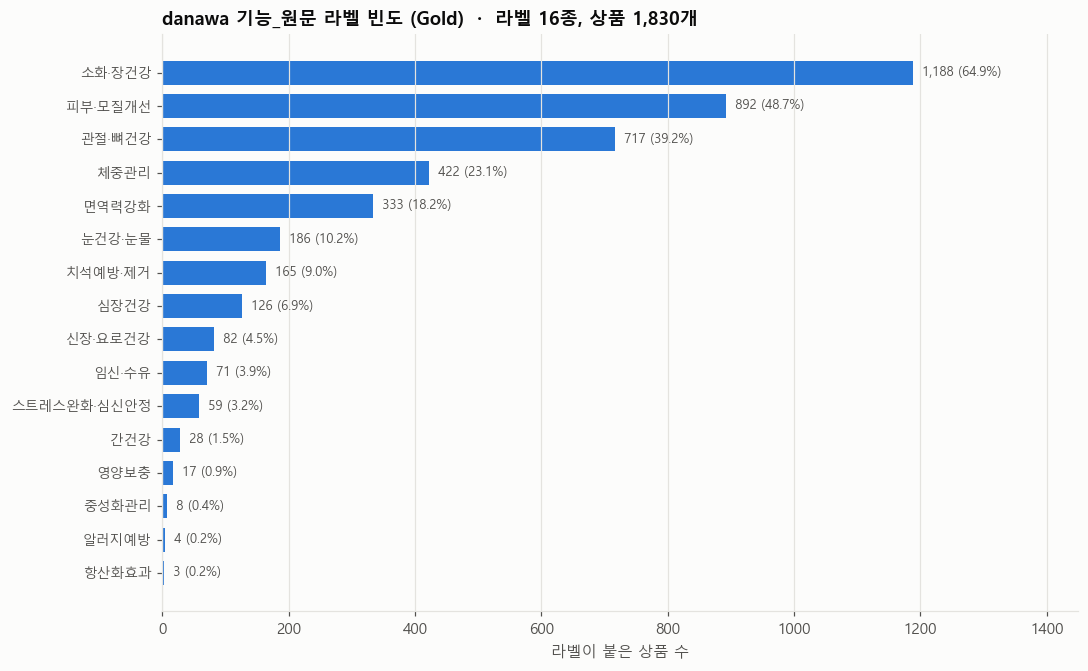

저장: figures\function_label_freq_danawa.png


In [5]:
plot_label_freq("danawa")

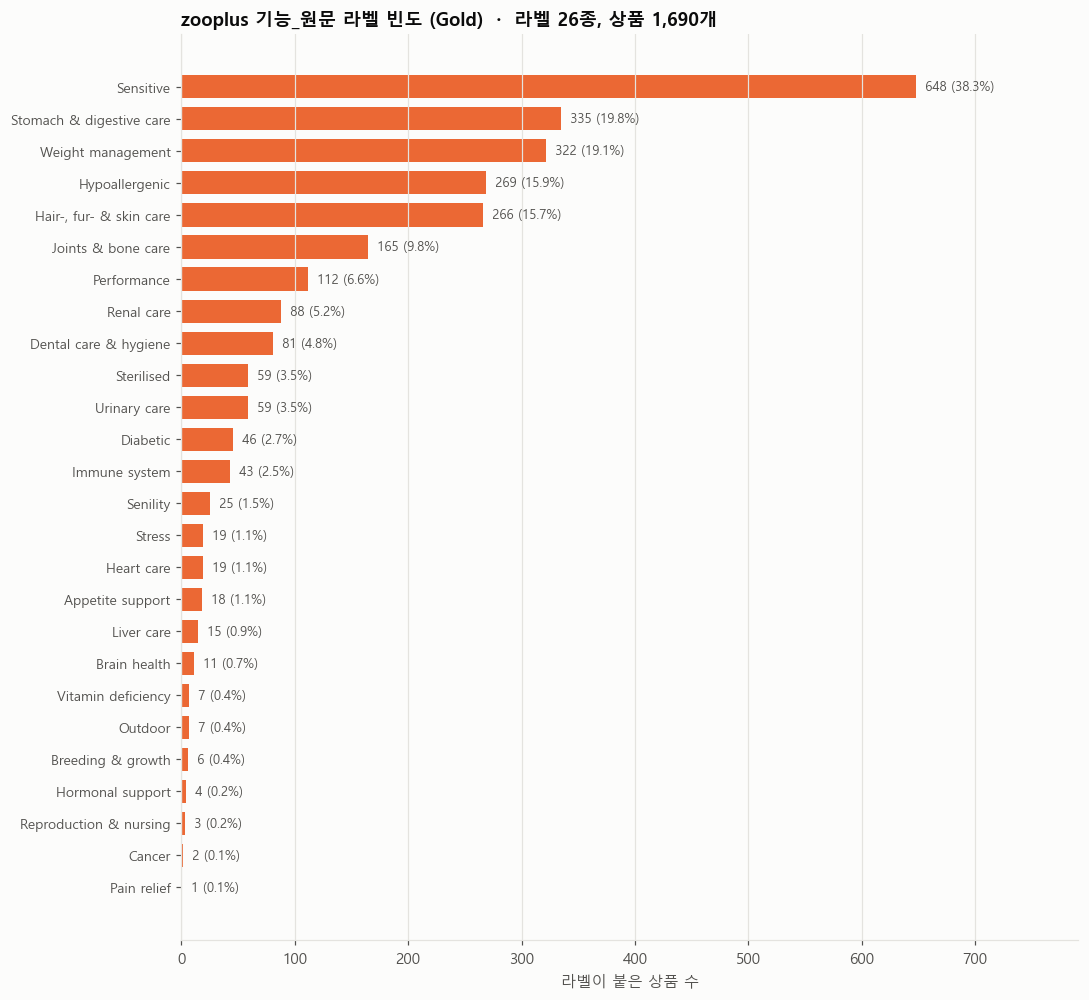

저장: figures\function_label_freq_zooplus.png


In [6]:
plot_label_freq("zooplus")

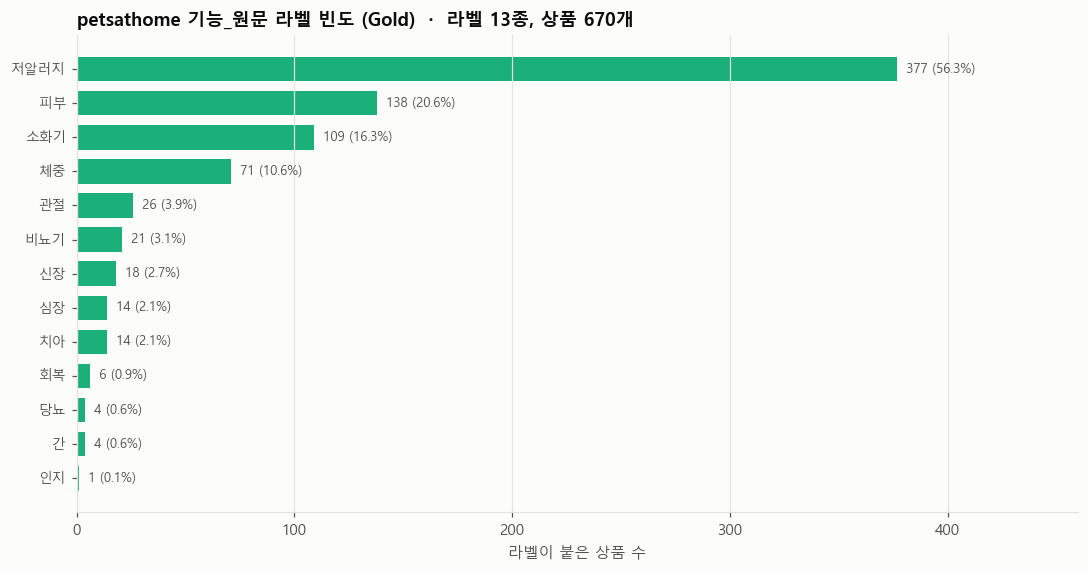

저장: figures\function_label_freq_petsathome.png


In [7]:
plot_label_freq("petsathome")

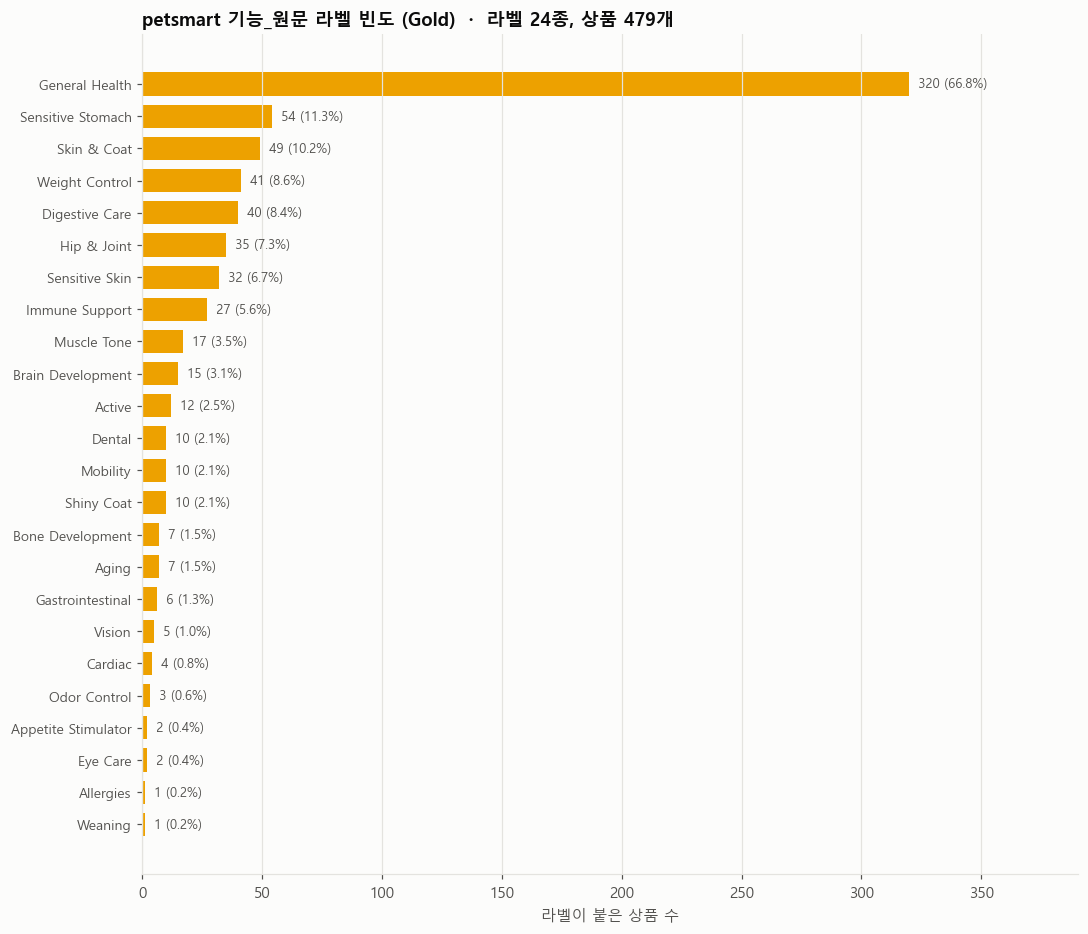

저장: figures\function_label_freq_petsmart.png


In [8]:
plot_label_freq("petsmart")

### 2-2. 전체 라벨 목록

In [9]:
label_table = (labels.groupby(["출처", "라벨"], observed=True).size().rename("상품_수").reset_index()
               .sort_values(["출처", "상품_수"], ascending=[True, False]))
label_table["출처_내_비율_%"] = (label_table["상품_수"] / label_table["출처"].astype(str).map(n_products.to_dict()) * 100).round(1)
label_table.reset_index(drop=True)

,출처,라벨,상품_수,출처_내_비율_%
0,danawa,소화·장건강,1188,64.9
1,danawa,피부·모질개선,892,48.7
2,danawa,관절·뼈건강,717,39.2
3,danawa,체중관리,422,23.1
4,danawa,면역력강화,333,18.2
5,danawa,눈건강·눈물,186,10.2
6,danawa,치석예방·제거,165,9.0
7,danawa,심장건강,126,6.9
8,danawa,신장·요로건강,82,4.5
9,danawa,임신·수유,71,3.9


### 2-3. 관찰

- **라벨 어휘가 출처마다 완전히 다르다.** 79종 중 두 출처 이상에 함께 나오는 라벨은 없다. 같은 개념도 출처별로 이름이 다르다.
  - 소화: `소화·장건강`(다나와) / `Stomach & digestive care`(Zooplus) / `소화기`(Pets at Home) / `Digestive Care`·`Sensitive Stomach`·`Gastrointestinal`(PetSmart)
  - 피부·모질: `피부·모질개선` / `Hair-, fur- & skin care` / `피부` / `Skin & Coat`·`Sensitive Skin`·`Shiny Coat`
  - 관절: `관절·뼈건강` / `Joints & bone care` / `관절` / `Hip & Joint`·`Mobility`·`Bone Development`
- **건강 기능이 아닌 라벨이 상위권에 섞여 있다.** Zooplus `Sensitive`(가장 많음)·`Hypoallergenic`·`Performance`·`Sterilised`, Pets at Home `저알러지`(가장 많음), PetSmart `General Health`(가장 많음)는 식이·대상 특성이나 포괄 태그다. `training_dataset_summary.md`는 이들을 건강 기능 정답과 분리하도록 정했다.
- **빈도가 낮은 라벨이 길게 이어진다.** `Pain relief`, `인지`, `Allergies`, `Weaning`처럼 1~3건인 라벨은 단독으로는 학습할 수 없다.
- 따라서 원문 라벨을 그대로 정답으로 쓸 수 없고, 표준 카테고리(digestive, skin_coat, joint_bone 등)로 묶어야 한다 (3절).

## 3. 표준 카테고리 정리

원문 라벨 79종을 `기능카테고리사전.csv`로 표준 카테고리에 묶고, 학습에 쓸 카테고리를 정량 기준으로 고른다.
매핑 결과는 통합 데이터의 `기능카테고리` 컬럼(건강기능 카테고리 전체)에 들어 있다. 기준의 상세 근거는 `project/md/function_category_criteria.md`에 있다.

**집계 기준**
- 건강기능(`유형=health_function`) 카테고리만 센다. `Sensitive`·`General Health`·`Hypoallergenic` 같은 식이특성·포괄 태그는 정의상 제외한다.
- 동의어를 먼저 합친 뒤, 상품 단위로 센다 (한 상품에 같은 카테고리 원문이 여러 개여도 1건). 다나와 `신장·요로건강`은 renal·urinary 두 카테고리에 함께 매핑된다.
- 중복 상품(`중복여부=True`)은 제외한다.

**채택 기준: 모비율 신뢰구간**
- 카테고리별 재현율을 5-fold 교차검증으로 추정할 때, 95% 신뢰수준에서 오차가 ±10%p(탐색적 연구 관례) 이내여야 한다.
- 필요한 양성 수: $n = z^2 p(1-p) / E^2 = 1.96^2 \times 0.25 / 0.10^2 \approx 96.04 \rightarrow 97$건
- 5-fold 교차검증은 모든 상품을 한 번씩 평가하므로, 전체 상품 수 $N \ge 97$이면 채택한다.

In [10]:
Z, P, E_MAX = 1.96, 0.5, 0.10    # 신뢰수준 95%, 가장 보수적인 p, 허용 오차 ±10%p
TEST_RATIO_82 = 0.2               # 비교용: 8:2 단일 분할의 테스트 비율
N_MIN = int(np.ceil(Z**2 * P * (1 - P) / E_MAX**2))
print(f"카테고리별 최소 양성 수: {N_MIN}")

dictionary = pd.read_csv("../data/model_datasets/기능카테고리사전.csv", encoding="utf-8-sig")
category_name = dictionary.drop_duplicates("카테고리").set_index("카테고리")["카테고리명"]
print(f"사전에 없는 원문 라벨이 있는 상품: {df['품질플래그'].fillna('').str.contains('기능라벨_사전없음').sum()}개")

health = (df.loc[df["중복여부"] != True, ["출처", "상품ID", "기능카테고리"]].dropna()
          .assign(카테고리=lambda t: t["기능카테고리"].str.split("|")).explode("카테고리"))
health["출처"] = health["출처"].astype(str)
by_source = health.pivot_table(index="카테고리", columns="출처", values="상품ID", aggfunc="size", fill_value=0)
by_source = by_source.reindex(columns=SOURCE_ORDER, fill_value=0)

cat = pd.DataFrame({"상품수": by_source.sum(axis=1)}).sort_values("상품수", ascending=False)
cat.insert(0, "이름", cat.index.map(category_name))
cat["누적비율_%"] = (cat["상품수"].cumsum() / cat["상품수"].sum() * 100).round(1)
cat["출처수"] = (by_source.loc[cat.index] > 0).sum(axis=1)
cat["최대출처비중_%"] = (by_source.loc[cat.index].max(axis=1) / cat["상품수"] * 100).round(0)
cat["오차_5fold"] = (Z * np.sqrt(P * (1 - P) / cat["상품수"])).round(3)
cat["오차_8대2"] = (Z * np.sqrt(P * (1 - P) / (cat["상품수"] * TEST_RATIO_82))).round(3)
cat["판정"] = np.where(cat["상품수"] >= N_MIN, "채택", "보류")
adopted = cat.index[cat["판정"] == "채택"].tolist()
print(f"채택 {len(adopted)}개, 보류 {len(cat) - len(adopted)}개 / 채택 카테고리가 건강기능 라벨의 "
      f"{cat.loc[adopted, '상품수'].sum() / cat['상품수'].sum() * 100:.1f}% 차지")

# 사전의 학습채택(→ 통합 데이터의 학습카테고리)이 이 기준으로 다시 계산한 판정과 같은지 확인
dict_adopted = set(dictionary.loc[dictionary["학습채택"] == "adopted", "카테고리"])
print(f"사전의 학습채택과 일치: {set(adopted) == dict_adopted}")
cat

카테고리별 최소 양성 수: 97
사전에 없는 원문 라벨이 있는 상품: 0개
채택 10개, 보류 8개 / 채택 카테고리가 건강기능 라벨의 97.1% 차지
사전의 학습채택과 일치: True


,이름,상품수,누적비율_%,출처수,최대출처비중_%,오차_5fold,오차_8대2,판정
카테고리,,,,,,,,
digestive,소화·장 건강,1508,27.2,4,79.0,0.025,0.056,채택
skin_coat,피부·모질,1171,48.2,4,76.0,0.029,0.064,채택
joint_bone,관절·뼈,856,63.7,4,84.0,0.033,0.075,채택
weight_management,체중 관리,652,75.4,4,65.0,0.038,0.086,채택
immune,면역,387,82.4,3,86.0,0.050,0.111,채택
dental_oral,치아·구강,221,86.3,4,75.0,0.066,0.147,채택
vision,눈 건강,191,89.8,2,97.0,0.071,0.159,채택
heart,심장,149,92.5,4,85.0,0.080,0.180,채택
renal,신장,138,95.0,3,59.0,0.083,0.187,채택


### 3-1. 카테고리별 상품 수와 채택 여부

파란 막대가 채택(97건 이상), 회색 막대가 보류다. 점선은 최소 양성 수 97건이다.

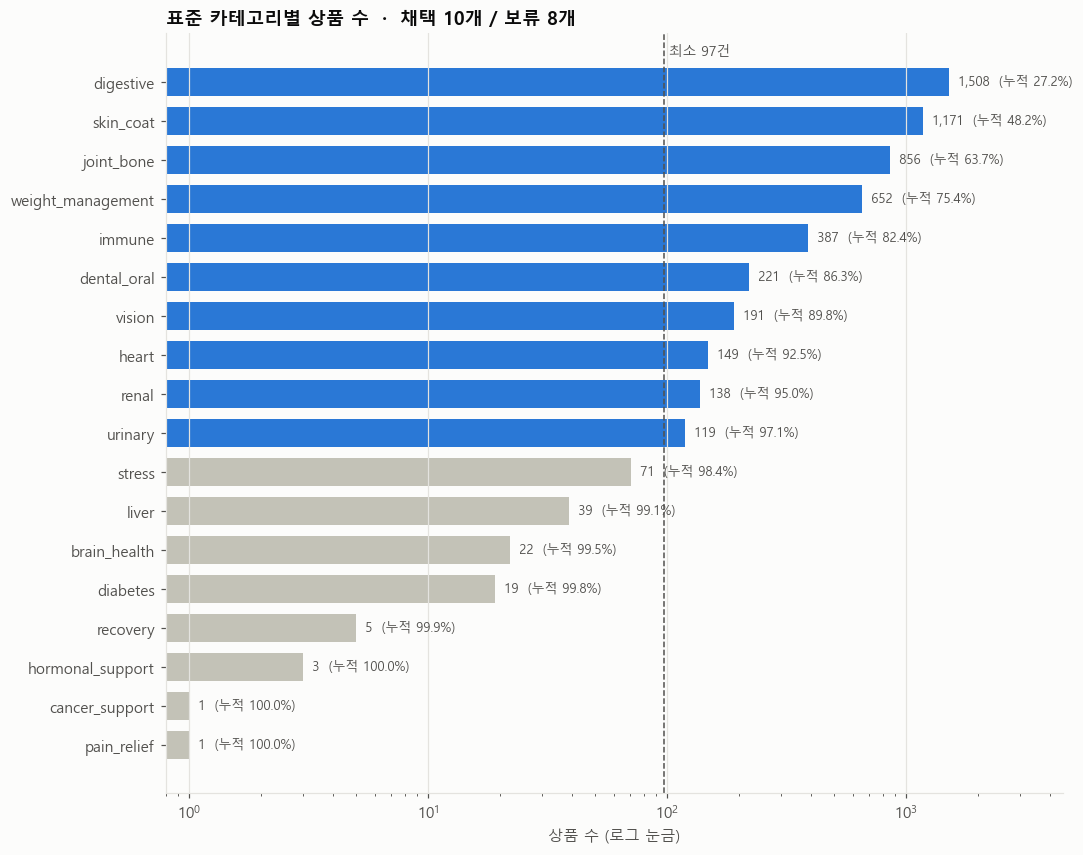

In [11]:
ADOPT, HOLD = "#2a78d6", "#c3c2b7"
vc = cat["상품수"].iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 0.36 * len(vc) + 1.4))
ax.barh(vc.index, vc.values, height=0.72,
        color=[ADOPT if c in adopted else HOLD for c in vc.index])
for y, (c, v) in enumerate(vc.items()):
    ax.text(v, y, f"  {v:,}  (누적 {cat.at[c, '누적비율_%']:.1f}%)", va="center", fontsize=8.5, color=INK2)
ax.axvline(N_MIN, color=INK2, lw=1, ls="--")
ax.text(N_MIN, len(vc) - 0.4, f" 최소 {N_MIN}건", fontsize=9, color=INK2, va="bottom")
ax.set_xscale("log")
ax.set_xlim(0.8, vc.max() * 3)
ax.set_xlabel("상품 수 (로그 눈금)")
ax.set_title(f"표준 카테고리별 상품 수  ·  채택 {len(adopted)}개 / 보류 {len(cat) - len(adopted)}개")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "category_counts.png", dpi=150)
plt.show()

### 3-2. 카테고리별 신뢰구간 오차

같은 상품 수로 재현율을 추정할 때의 95% 신뢰구간 반폭이다. 5-fold 교차검증은 모든 상품을 평가하고, 8:2 단일 분할은 20%만 평가하므로 오차가 약 2.2배($\sqrt{5}$배) 크다.
점선(±0.10)보다 왼쪽이면 기준 충족이다. 오차가 0.5를 넘는 카테고리는 잘라서 표시했다.

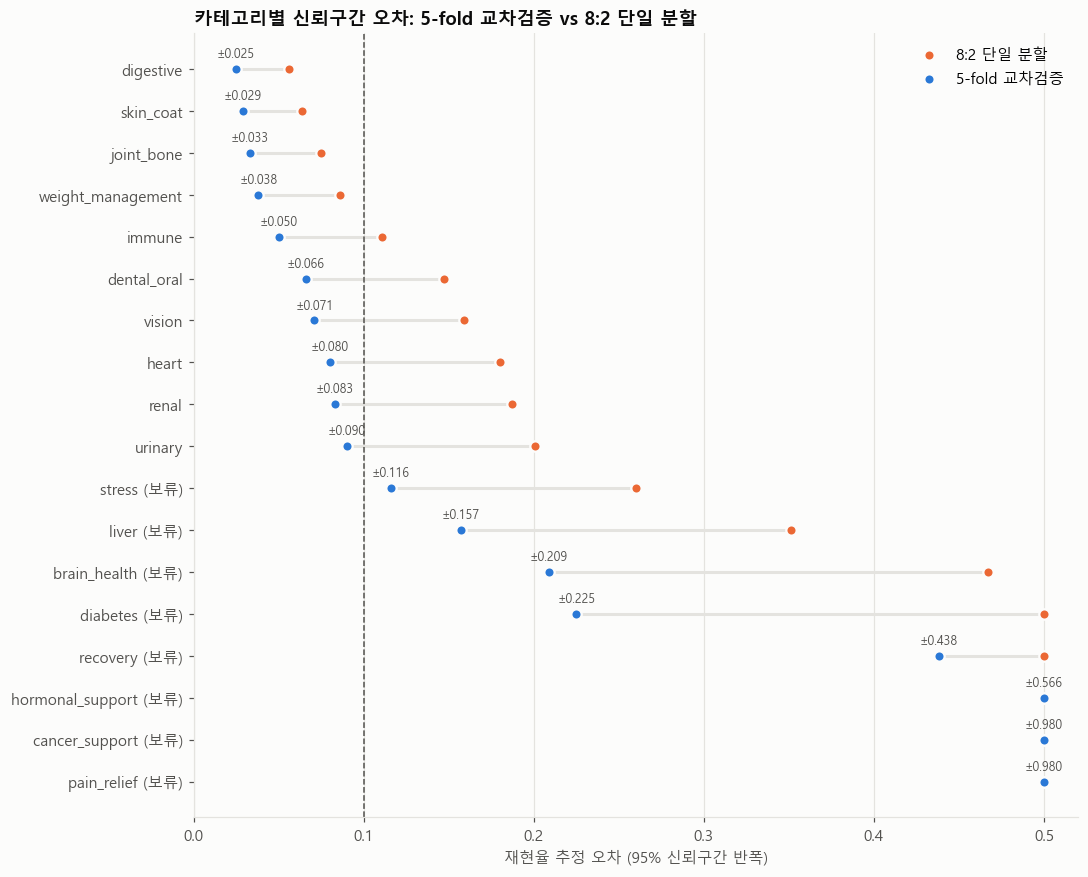

In [12]:
COLOR_CV, COLOR_82 = "#2a78d6", "#eb6834"
err = cat[["오차_5fold", "오차_8대2"]].iloc[::-1]
CLIP = 0.5
fig, ax = plt.subplots(figsize=(10, 0.36 * len(err) + 1.6))
y = np.arange(len(err))
ax.hlines(y, err["오차_5fold"].clip(upper=CLIP), err["오차_8대2"].clip(upper=CLIP), color=GRID, lw=2)
ax.scatter(err["오차_8대2"].clip(upper=CLIP), y, s=46, color=COLOR_82, label="8:2 단일 분할", zorder=3,
           edgecolor=SURFACE, linewidth=1.5)
ax.scatter(err["오차_5fold"].clip(upper=CLIP), y, s=46, color=COLOR_CV, label="5-fold 교차검증", zorder=3,
           edgecolor=SURFACE, linewidth=1.5)
for yi, v in zip(y, err["오차_5fold"]):
    ax.text(min(v, CLIP), yi + 0.28, f"±{v:.3f}", fontsize=8, color=INK2, ha="center")
ax.axvline(E_MAX, color=INK2, lw=1, ls="--")
ax.set_yticks(y, [f"{c}{'' if c in adopted else ' (보류)'}" for c in err.index])
ax.set_xlim(0, CLIP + 0.02)
ax.set_xlabel("재현율 추정 오차 (95% 신뢰구간 반폭)")
ax.set_title("카테고리별 신뢰구간 오차: 5-fold 교차검증 vs 8:2 단일 분할")
ax.legend(loc="upper right", frameon=False)
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "category_ci_error.png", dpi=150)
plt.show()

### 3-3. 채택 카테고리의 출처 구성

한 출처에 치우친 카테고리는 모델이 기능 대신 "어느 사이트 데이터인지"를 배울 위험이 있다.

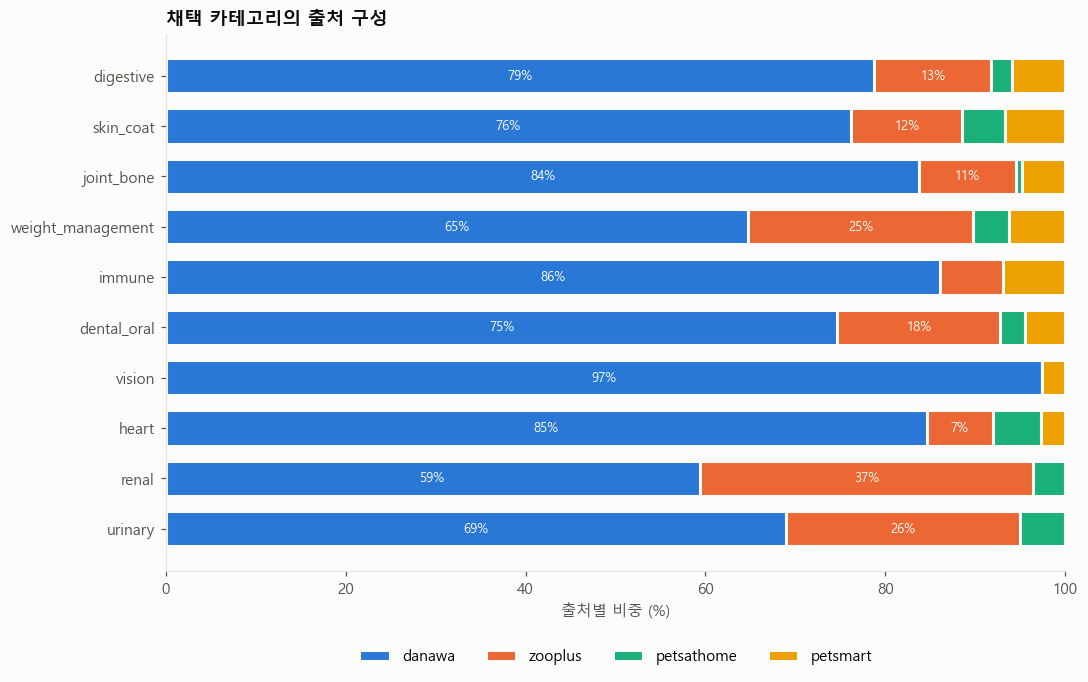

In [13]:
share = by_source.loc[adopted[::-1]].div(by_source.loc[adopted[::-1]].sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(10, 0.45 * len(share) + 1.8))
left = np.zeros(len(share))
for s in SOURCE_ORDER:
    ax.barh(share.index, share[s], left=left, height=0.7, color=SOURCE_COLOR[s], label=s,
            edgecolor=SURFACE, linewidth=2)
    for yi, (v, l) in enumerate(zip(share[s], left)):
        if v >= 7:
            ax.text(l + v / 2, yi, f"{v:.0f}%", ha="center", va="center", fontsize=8.5, color="white")
    left += share[s].to_numpy()
ax.set_xlim(0, 100)
ax.set_xlabel("출처별 비중 (%)")
ax.set_title("채택 카테고리의 출처 구성")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
ax.grid(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "category_source_share.png", dpi=150)
plt.show()

### 3-4. 원문 라벨 → 채택 카테고리 매핑 (`기능카테고리사전.csv`)

In [14]:
mapping_table = (dictionary[dictionary["학습채택"] == "adopted"]
                 .groupby(["카테고리", "출처"])["원문라벨"].agg(lambda s: ", ".join(sorted(s)))
                 .unstack("출처").reindex(index=adopted, columns=SOURCE_ORDER).fillna("—"))
mapping_table.insert(0, "이름", mapping_table.index.map(category_name))
mapping_table

출처,이름,danawa,zooplus,petsathome,petsmart
카테고리,,,,,
digestive,소화·장 건강,소화·장건강,Stomach & digestive care,소화기,"Digestive Care, Gastrointestinal, Sensitive St..."
skin_coat,피부·모질,피부·모질개선,"Hair-, fur- & skin care",피부,"Sensitive Skin, Shiny Coat, Skin & Coat"
joint_bone,관절·뼈,관절·뼈건강,Joints & bone care,관절,"Bone Development, Hip & Joint, Mobility"
weight_management,체중 관리,체중관리,Weight management,체중,Weight Control
immune,면역,면역력강화,Immune system,—,Immune Support
dental_oral,치아·구강,치석예방·제거,Dental care & hygiene,치아,Dental
vision,눈 건강,눈건강·눈물,—,—,"Eye Care, Eye Health, Vision"
heart,심장,심장건강,Heart care,심장,"Cardiac, Heart Health"
renal,신장,신장·요로건강,Renal care,신장,—


### 3-5. 상품별 카테고리 채택 현황

Gold 상품을 카테고리 상태에 따라 세 그룹으로 나눈다.

| 그룹 | 조건 |
| --- | --- |
| 채택 | `학습카테고리`가 있음 (채택 카테고리가 1개 이상) |
| 미채택 | `기능카테고리`는 있지만 모두 보류 카테고리 (`학습카테고리` 없음) |
| 카테고리 없음 | `기능카테고리`가 없음 (건강기능이 아닌 라벨만 있음) |

In [15]:
GROUPS = ["채택", "미채택 (보류 카테고리만)", "카테고리 없음 (비기능 라벨만)"]
df["카테고리_상태"] = pd.Categorical(
    np.select([df["학습카테고리"].notna(), df["기능카테고리"].notna()], GROUPS[:2], default=GROUPS[2]),
    categories=GROUPS)

status = pd.crosstab(df["카테고리_상태"], df["출처"], margins=True, margins_name="합계")
status["비율_%"] = (status["합계"] / len(df) * 100).round(1)
status

출처,danawa,zooplus,petsathome,petsmart,합계,비율_%
카테고리_상태,,,,,,
채택,1796,996,373,188,3353,71.8
미채택 (보류 카테고리만),17,41,13,2,73,1.6
카테고리 없음 (비기능 라벨만),17,653,284,289,1243,26.6
합계,1830,1690,670,479,4669,100.0


In [16]:
# 미채택 그룹의 카테고리, 카테고리 없음 그룹의 원문 라벨
held = df.loc[df["카테고리_상태"] == GROUPS[1], "기능카테고리"].str.split("|").explode().value_counts()
no_cat = df.loc[df["카테고리_상태"] == GROUPS[2], "기능_원문"].str.split("|").explode().value_counts()
display(held.rename("상품 수").rename_axis("미채택 그룹의 보류 카테고리").to_frame())
no_cat.head(10).rename("상품 수").rename_axis("카테고리 없음 그룹의 원문 라벨 (상위 10)").to_frame()

,상품 수
미채택 그룹의 보류 카테고리,
liver,24
stress,23
diabetes,15
recovery,4
brain_health,4
cancer_support,2
pain_relief,1


,상품 수
카테고리 없음 그룹의 원문 라벨 (상위 10),
Sensitive,412
저알러지,284
General Health,283
Hypoallergenic,184
Performance,76
Senility,20
Sterilised,17
임신·수유,13
Appetite support,10


### 3-6. 관찰

- 기준(95% 신뢰수준, ±10%p, 5-fold 교차검증)을 적용하면 **10개 카테고리**가 채택되고, 이들이 건강기능 라벨의 97.1%를 차지한다. 11위 stress(71건)는 오차 ±0.116으로 기준을 넘는다.
- 같은 상품 수라도 8:2 단일 분할로 평가하면 오차가 약 2.2배($\sqrt{5}$배) 커서, 4개만 기준을 충족한다.
- **모든 채택 카테고리에서 다나와 비중이 가장 크다** (59~97%). 특히 vision은 97%가 다나와라서 출처 편향의 위험이 가장 크다.
- 다나와 `신장·요로건강`이 renal·urinary에 함께 매핑되어, 다나와의 renal 82건과 urinary 82건은 같은 상품이다. 다나와 데이터만으로는 두 기능을 구분할 수 없다.
- 교차검증의 오차는 회차 간 학습 데이터가 겹쳐 실제보다 약간 낙관적인 근사값이다.